# Pytorch 
- Intially developed by Meta but now maintained by Linix foundation
- pytorch works similar to numpy
- here Tensor is similar to an array or matrix
- it is the building blocks of neural networks
- when doing any aggregation with the tensors the shape must be compatible to do any operation (2x2) +(2x2) will work, not (2x3) + (3x3)
- input neuron are the features and output neurons are the output classes we want to predict

In [1]:
# Import PyTorch
import torch

temperatures = [[72, 75, 78], [70, 73, 76]]
print(temperatures)

# Create a tensor from temperatures
temp_tensor = torch.tensor(temperatures)

print(temp_tensor)

[[72, 75, 78], [70, 73, 76]]
tensor([[72, 75, 78],
        [70, 73, 76]])


In [2]:
# View the shape of the tensor
print(temp_tensor.shape)

torch.Size([2, 3])


In [3]:
# view the datatype 
print(temp_tensor.dtype)

torch.int64


In [4]:
# Adding Tensor with same shape and dtype
adjustment = torch.tensor([[2, 2, 2], [2, 2, 2]])
corrected_temperatures = temp_tensor + adjustment
print("Corrected temperatures:", corrected_temperatures)

Corrected temperatures: tensor([[74, 77, 80],
        [72, 75, 78]])


In [4]:
# Neural Networks and Layers - Fully connected network which is equlivaent to Linear model
# importing as nn to avoid writing torch.nn
import torch.nn as nn

# Create input_tensor with three features
input_tensor = torch.tensor(
    [[0.3471, 0.4547, -0.2356]]
)

# Define one linear layer
linear_layer = nn.Linear(
    in_features = 3,
    out_features = 2
)

# pass input through linear layer
output = linear_layer(input_tensor)
print(output)

tensor([[0.0408, 0.5119]], grad_fn=<AddmmBackward0>)


In [6]:
# when the inputs are provide to the linear_layer , a linear operation is performed ( output(y) = input(x) * weights(m) + Biases(b) ).
# So each linear layer has its own set of weights and biases 
# - Weight is the importance of the diffreny features
# - Bias is the neuron with baseline output
print(linear_layer.weight)
print(linear_layer.bias)

Parameter containing:
tensor([[ 0.4434, -0.2043, -0.1642],
        [-0.0989, -0.1669,  0.0283]], requires_grad=True)
Parameter containing:
tensor([-0.5764, -0.4124], requires_grad=True)


In [7]:
# Random weights assigned if we run second time whihc will be tuned later
print(linear_layer.weight)
print(linear_layer.bias)

Parameter containing:
tensor([[ 0.4434, -0.2043, -0.1642],
        [-0.0989, -0.1669,  0.0283]], requires_grad=True)
Parameter containing:
tensor([-0.5764, -0.4124], requires_grad=True)


In [8]:
# Hidden Lyers and Parameters
# We can add as many hidden layers as we like as long as the input dimension of each layer matches the output dimension of the previous one.
n_features = 4
n_classes = 2
model = nn.Sequential(
    nn.Linear(n_features, 8),
    nn.Linear(8,4),
    nn.Linear(4, n_classes)
)
# A signle neuron has n+1 learnable paramters ( n from output dimention of previous inputs layer and 1 from the bias)
# More hidden layers = more parameters = higher model capacity - this takes longer to train
# to select the optimal model capacity is to calculating the total number of paramters

## Manual Calculation of the parameters 
### from the above layers 
    - First layer has 4 neurons and 8+1 parametrs which is 9 times 4 = 36 parms
    - Second Layer has 4 neurons and 8+1 parametrs which is 9 times 4 = 36 parms
    - Output layer has 2 neurons and 4+1 parameters which is 5 times 2 = 10
- gives us 86 learnable paramters

In [9]:
# Calculating using PyTorch method .numel()
total = 0
for parameter in model.parameters():
    total += parameter.numel()
print(total)

86


#### Balancing complexity and efficency
- Too many params lead to long training time or overfitting while too few might limit the learning capacity 

In [10]:
model1 = nn.Sequential(nn.Linear(9, 4),
                      nn.Linear(4, 2),
                      nn.Linear(2, 1))

In [11]:
total = 0
for p in model1.parameters():
    total += p.numel()
    
print(total)

53


# Activation Functions
- Activation Function add non -linearity to the network
      - Sigmoid for binary classification ( either 0 or 1)
      - Softmax for multi-class Classification
- A network can learn more complex relationship with non-linearity
- 'Pre-Activation' output passed to the activation function

In [12]:
# Sigmoid Activation Implementation
sigmoid = nn.Sigmoid()
##################################
n_features = 4
n_classes = 2
model = nn.Sequential(
    nn.Linear(n_features, 8),
    nn.Linear(8,4),
    nn.Linear(4, n_classes),    
    nn.Sigmoid()
)

# Softmax Activation Implementation
softmax = nn.Softmax(dim=-1)
###################################
n_features = 4
n_classes = 2
model = nn.Sequential(
    nn.Linear(n_features, 8),
    nn.Linear(8,4),
    nn.Linear(4, n_classes),
    nn.Softmax(dim = -1)
)

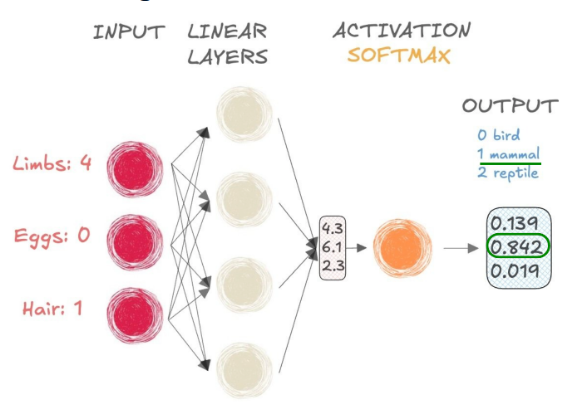

#### Running a forward pass
- Regression : forward pass
- Classification : Forward pass

In [13]:
# Regression : forward pass

input_tensor = torch.Tensor([[3, 4, 6, 7, 10, 12, 2, 3, 6, 8, 9]])

# Update network below to perform a multi-class classification with four labels
model = nn.Sequential(
  nn.Linear(11, 20),
  nn.Linear(20, 12),
  nn.Linear(12, 6),
  nn.Linear(6, 1),
)

output = model(input_tensor)
print(output)

tensor([[-0.0146]], grad_fn=<AddmmBackward0>)


In [14]:
# Classification : Forward pass

input_tensor = torch.Tensor([[3, 4, 6, 7, 10, 12, 2, 3, 6, 8, 9]])

# Update network below to perform a multi-class classification with four labels
model = nn.Sequential(
  nn.Linear(11, 20),
  nn.Linear(20, 12),
  nn.Linear(12, 6),
  nn.Linear(6, 4),
  nn.Softmax(dim = -1)
)

output = model(input_tensor)
print(output)

tensor([[0.4270, 0.1360, 0.4099, 0.0270]], grad_fn=<SoftmaxBackward0>)


# Using Loss Function to assess model prediction
- Tell how good a model is during training
- takes a model prediction y^ and ground truth y
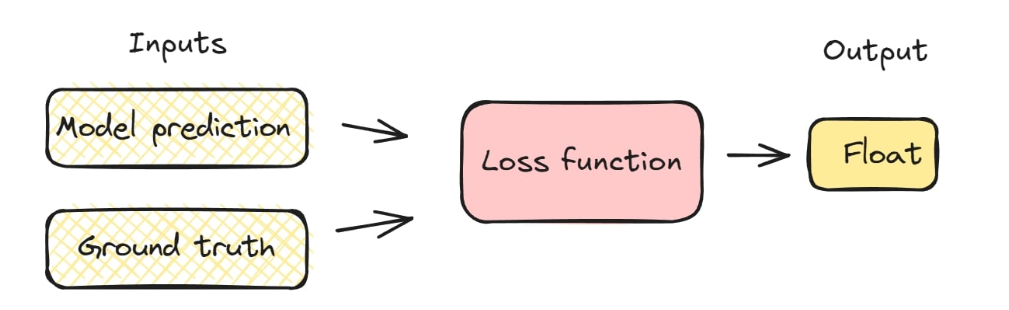

# CrossentropyLoss used for multiclass classification
# Loss Function  takes  
- scores - model prediction before the final softmax function and one-hot-target fround truth label and give output as a single float loss
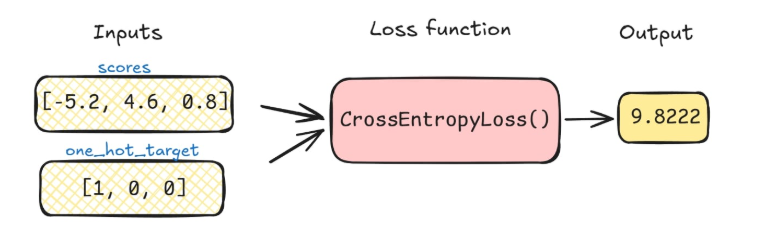

In [2]:
# Implementation
import torch
import torch.nn.functional as F
from torch.nn import CrossEntropyLoss

y = [2]
scores = torch.tensor([[0.1, 6.0, -2.0, 3.2]])

# Create a one-hot encoded vector of the label y
one_hot_label = F.one_hot(torch.tensor(y), num_classes=4)

# Create the cross entropy loss function
criterion = CrossEntropyLoss()

# Calculate the cross entropy loss
loss = criterion(scores.double(), one_hot_label.double())
print(loss)

tensor(8.0619, dtype=torch.float64)


### Using Derivatives to update model parameters
- Using Derivative or gradient to find the global minima to find the lowest point in the Loss function ( non-convex function)

In [ ]:
# Calculate the loss and gradients 
prediction = torch.tensor([[2, 2, 2], [2, 2, 2]], dtype=torch.float32)
target = torch.tensor([2, 2])
criterion = CrossEntropyLoss()
loss = criterion(prediction, target)
loss.backward()

import torch.optim as optim

optimizer = optim.SGD(model.parameters(), lr= 0.001)

#Perform parameter updates
optimizer.step()

In [22]:
model = nn.Sequential(nn.Linear(16, 8),
                      nn.Linear(8, 4),
                      nn.Linear(4, 2)
                     )

# Access the weight of the first linear layer
weight_0 = model[0].weight
print("Weight of the first layer:", weight_0)

# Access the bias of the second linear layer
bias_1 = model[1].bias
print("Bias of the second layer:", bias_1)

Weight of the first layer: Parameter containing:
tensor([[ 0.1595, -0.2364,  0.0127,  0.2094, -0.0913, -0.0339,  0.2333,  0.2390,
         -0.2045, -0.0863, -0.1270, -0.1555,  0.1401, -0.0215, -0.1272, -0.0672],
        [-0.2444, -0.1673,  0.0925,  0.0336,  0.1762,  0.0041,  0.0527, -0.0566,
         -0.0884,  0.1865,  0.1582, -0.2431,  0.0938,  0.0801,  0.2373,  0.2394],
        [-0.2108,  0.1651, -0.0966,  0.0037, -0.2093, -0.1914,  0.0024, -0.2355,
          0.2396,  0.0124, -0.0485,  0.2422,  0.1628, -0.2094,  0.1880,  0.2067],
        [-0.0771, -0.1554, -0.1707,  0.0823,  0.1123, -0.0192,  0.2384, -0.0581,
         -0.1327,  0.0205,  0.1934,  0.0042,  0.1562,  0.0520, -0.0950, -0.0273],
        [ 0.1871,  0.0796, -0.2244,  0.0884, -0.1432,  0.1830, -0.1854,  0.0569,
          0.0803,  0.0730,  0.1458, -0.0752, -0.1976,  0.0020, -0.0285, -0.1326],
        [-0.2219,  0.1756, -0.0136,  0.2329, -0.1824,  0.1784,  0.1383,  0.0067,
          0.0449,  0.1265, -0.0495, -0.0004, -0.2261,  

In [ ]:
lr = 0.001
weight0 = model[0].weight
weight1 = model[1].weight
weight2 = model[2].weight

# Access the gradients of the weight of each linear layer
grads0 = weight0.grad
grads1 = weight1.grad
grads2 = weight2.grad

# Update the weights using the learning rate and the gradients
weight0 = weight0 - (lr * grads0)
weight1 = weight1 - (lr * grads1)
weight2 = weight2 - (lr * grads2)

In [ ]:
# Create the optimizer
import torch.optim as optim
optimizer = optim.SGD(model.parameters(), lr=0.001)

loss = criterion(pred, target)
loss.backward()

# Update the model's parameters using the optimizer
optimizer.step()

# Training a DL

In [26]:
import os

os.getcwd()

'E:\\Files\\Jobs - 2026\\Models\\notebooks\\AI_ENGINEERING'

In [27]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
path = "../../data/Processed/phishing_websites_dataset"
X = pd.read_csv(path + "/X.csv")
y = pd.read_csv(path + "/y.csv")
print(X.shape)
print(y.shape)

(11055, 30)
(11055, 1)


In [29]:
# Converting it into numpy array for easy handling
X = X.to_numpy()
y = y.to_numpy()
print(X)
print(y)

[[-1  1  1 ...  1  1 -1]
 [ 1  1  1 ...  1  1  1]
 [ 1  0  1 ...  1  0 -1]
 ...
 [ 1 -1  1 ...  1  0  1]
 [-1 -1  1 ...  1  1  1]
 [-1 -1  1 ... -1  1 -1]]
[[-1]
 [-1]
 [-1]
 ...
 [-1]
 [-1]
 [-1]]


In [30]:
from torch.utils.data import TensorDataset, DataLoader # allows to store as Tensors, easy to manage and manege data loading 

dataset = TensorDataset(torch.tensor(X), torch.tensor(y))

# Access an individual sample
input_sample, label_sample = dataset[0]
print('input sample', input_sample)
print('label_sample', label_sample)

input sample tensor([-1,  1,  1,  1, -1, -1, -1, -1, -1,  1,  1, -1,  1, -1,  1, -1, -1, -1,
         0,  1,  1,  1,  1, -1, -1, -1, -1,  1,  1, -1])
label_sample tensor([-1])


In [ ]:
batch_size = 2
shuffle = True
# print each batch of inputs and labels.
# Create a DataLoader
dataloader = DataLoader(dataset, shuffle = True, batch_size = batch_size)

# Iterate over the dataloader
for batch_inputs, batch_labels in dataloader:
    print('batch_inputs:', batch_inputs)
    print('batch_labels:', batch_labels)

In [ ]:
# MSE Losss for Regression problems - which is calculated by 
def mean_squared_loss(prediction, target):
    return np.mean((prediction - target)**2)

# In pytorch we use
criterion = nn.MSELoss()
loss = criterion(prediction, target) # Note that both predictions and targets must be float tensors.

# Activation functions 
- Sigmoid and softmax
- Limitations of the sigmoid and softmax function
  - Output is bounded between 0 to 1
  - Usable in a network
  - Gradients - very small for large and small values of x
  - Causes saturation, leading to the vanishing gradient problem

## ReLU ( Rectified Linear Unit)
$$
f(x) =
\begin{cases}
x, & x \geq 0 \\
0, & x < 0
\end{cases}
$$
- so for postive Inputs : output equals to input ; for negative inputs : output will be 0 
- This helps to overcome the vanishing gradients problem

In Pytorch :
relu = nn.ReLU()

## Leaky ReLU (Leaky Rectified Linear Unit)
$$
f(x) =
\begin{cases}
x, & x \geq 0 \\
\alpha x, & x < 0
\end{cases}
$$

where $\alpha$ is a small positive constant, typically $\alpha = 0.01$.
- so for postive inputs behaves same as ReLU ; for negative input scalled by small coeeficent( default values is 0.01)
-  gradients for negative inputs are non-zero which help in not making dead neurons

In PyTorch :
leaky_relu = nn.LeakyReLU( negative_slope = 0.05)
- negative_slope is the coefficent value for negative input

# Learning Rate and Momentum

Training a ANN is updating the weights that is optimized for the problem. To do that we use Stochastic Gradient Descent (SGD) 

In Pytorch:
- sgd = optim.SGD(model.parameters(), lr = 0.01, momentun = 0.95)
- Learning Rate : contrls the step size ; momentum : uses previous updates to maintain direction, accelerate movement in consistent directions, and reduce oscillations.
- Typical Ranges : For Learning rate is from 0.01 to 0.0001 ; For momentum is 0.85 to 0.99

# Layer Intialization and Transfer Learning Rate
### Layer Intialization:
  - When we create an ANN layer we cannot start with zero weights because that causes problems with learning in NN
  - so PyTorch intializes random weights using intilization strategy; if there are large weights can make optimization difficult, particulary in sigmoid and tanh
  - Good initialization gives the network a sensible starting point for learning.
- Random + appropriately scaled weights → neurons can learn different features.
  - Xaiver/Glorot intilization
  - He/Kaiming intialization
  - Uniform intialization
  - Normal intialization

In [34]:
# Example - Initialize the weights using a uniform distribution between 0 and 1.
layer = nn.Linear(64, 128)
nn.init.uniform_(layer.weight, 0, 1)

print(layer.weight.min(), layer.weight.max())  # Initialize the weights using a uniform distribution between 0 and 1.

tensor(9.1970e-05, grad_fn=<MinBackward1>) tensor(0.9999, grad_fn=<MaxBackward1>)


## Transfer Learning
- Normal Training : Random weights ->  Train on European data -> European salary model
- Transfer Learning : US salary model ->  Already learned weights -> European salary data -> Continue training

In [35]:
model.state_dict() # Basically the weights are being transferred to the next model

OrderedDict([('0.weight',
              tensor([[ 0.1595, -0.2364,  0.0127,  0.2094, -0.0913, -0.0339,  0.2333,  0.2390,
                       -0.2045, -0.0863, -0.1270, -0.1555,  0.1401, -0.0215, -0.1272, -0.0672],
                      [-0.2444, -0.1673,  0.0925,  0.0336,  0.1762,  0.0041,  0.0527, -0.0566,
                       -0.0884,  0.1865,  0.1582, -0.2431,  0.0938,  0.0801,  0.2373,  0.2394],
                      [-0.2108,  0.1651, -0.0966,  0.0037, -0.2093, -0.1914,  0.0024, -0.2355,
                        0.2396,  0.0124, -0.0485,  0.2422,  0.1628, -0.2094,  0.1880,  0.2067],
                      [-0.0771, -0.1554, -0.1707,  0.0823,  0.1123, -0.0192,  0.2384, -0.0581,
                       -0.1327,  0.0205,  0.1934,  0.0042,  0.1562,  0.0520, -0.0950, -0.0273],
                      [ 0.1871,  0.0796, -0.2244,  0.0884, -0.1432,  0.1830, -0.1854,  0.0569,
                        0.0803,  0.0730,  0.1458, -0.0752, -0.1976,  0.0020, -0.0285, -0.1326],
                   

In [ ]:
# We save the above weights using
torch.save(model.state_dict(), "model.pth")

# we load them into another model by 
model.load_state_dict(torch.load("model.pth"))

# Fine Tuning
- Reuse the existing model and continue training some or all of its weights, usually with a smaller learning rate.
- Original model -> Learned weights -> New dataset -> Small learning rate -> Fine-tuned model
- A type of transfer Learning Rate
  - Samller Learning Rate - carefully adjusting existing knowledge rather than learning everything from scratch.
## Freezing Layers
- Example if in CNN
Layer 1 → edges 
Layer 2 → textures 
Layer 3 → shapes 
Layer 4 → complex patterns 
Output → specific classes
- the early layers already learned the usefull feature so we don't need to change the weights so we free them
- to learn more cmplex layere we update the unfrozen layer

In [5]:
# How do we freeze the layers in pytorch
model = nn.Sequential(
    nn.Linear(64, 128),
    nn.Linear(128, 256)
)
"""
Input (64)
   ↓
Linear 1: 64 → 128
   ↓
Linear 2: 128 → 256.

PyTorch automatically names them:
0.weight
0.bias
1.weight
1.bias


name          param
----------------------------
0.weight      weights of layer 1
0.bias        bias of layer 1
1.weight      weights of layer 2
1.bias        bias of layer 2
"""

for name, param in model.named_parameters():
    if name == '0.weight':
        param.requires_grad = False
"""
Layer 1
64 → 128
weight 🔒 FROZEN
bias   🔓 trainable

Layer 2
128 → 256
weight 🔓 trainable
bias   🔓 trainable
"""


"""
Why freeze early layers?
    Because early layers generally learn general features.
    for an image mode
        Early layers
            ↓
        edges
        lines
        textures
        basic shapes
    these features can be usefull across many image tasks
    Later layers tend to learn more task-specific features.
    For Example:
        Early:
        edge → texture → shape
        
        Later:
        "this looks like a car"
        "this looks like a pedestrian"
    So when transferring to a new but related task:

Keep the general knowledge and adapt the task-specific knowledge.

That's why the rule of thumb is:
    Early layers → freeze
    Later layers → fine-tune

-- Any how we need to have a good understand of the pretrained model archi and what thos weights represent in each layer like what they have trained on.
"""

'\nWhy freeze early layers?\n    Because early layers generally learn general features.\n    for an image mode\n        Early layers\n            ↓\n        edges\n        lines\n        textures\n        basic shapes\n    these features can be usefull across many image tasks\n    Later layers tend to learn more task-specific features.\n    For Example:\n        Early:\n        edge → texture → shape\n\n        Later:\n        "this looks like a car"\n        "this looks like a pedestrian"\n    So when transferring to a new but related task:\n\nKeep the general knowledge and adapt the task-specific knowledge.\n\nThat\'s why the rule of thumb is:\n    Early layers → freeze\n    Later layers → fine-tune\n\n-- Any how we need to have a good understand of the pretrained model archi and what thos weights represent in each layer like what they have trained on.\n'

| Concept               | Meaning                                                 |
| --------------------- | ------------------------------------------------------- |
| **Initialization**    | How weights are chosen before training                  |
| **Transfer Learning** | Reuse a trained model's knowledge for another task      |
| **Fine-tuning**       | Continue training the transferred model, usually gently |
| **Freezing**          | Prevent selected weights from being updated             |
| **Learning Rate**     | Controls how much weights change during training        |


# Evaluating model performance
- Training data can be around 80-90% of the data Adjust model parameters
- Validation data can be around 10-20% of the data to tune the hyperparameters
- Test data can be around 5-10% of the data to evaluate final model performance

#### In Evaluation we track two things LOSS and ACCURACY during traning and validation

#### Calculating training loss
- Before we need to understand what is a batch, Example suppose your training dataset is 1000 samples.
- so we set batch size to 100 samples ( 1 batch = 100 samples). we send 100 samples through the NN and make predictions and backpass is happening and optimize the weights. then we calculate the loss for that one epoch by adding all the 100 batches loss and dividing it by the number of batches which gives us the trainign loss for that one epoch.

In [ ]:
"""
                 EPOCH
                   │
        ┌──────────┼──────────┐
        ↓          ↓          ↓
     Batch 1    Batch 2    Batch 3 ... Batch N
        │          │          │
        ↓          ↓          ↓
     Forward     Forward     Forward
        ↓          ↓          ↓
      Loss       Loss       Loss
        │          │          │
        ↓          ↓          ↓
    Backward    Backward    Backward
        ↓          ↓          ↓
    Update      Update      Update
        │          │          │
        ↓          ↓          ↓
     0.80         0.60        0.40
        │          │          │
        └──────────┼──────────┘
                   ↓
             SUM LOSSES
                   ↓
                 1.80
                   ↓
             / number of
                batches
                   ↓
        AVERAGE TRAINING LOSS
"""

In [ ]:
# This what happens in one epoch but we need to add a loop for multiple epochs
# Calculating the trainign loss
training_loss = 0.0
model.train() # trainig mode
for inputs, labels in train_loader:
    optimizer.zero_grad() # Reset gradients
    # Run forward pass
    outputs = model(inputs)
    # compute loss
    loss = criterion(outputs, labels)
    #Backpropagation
    loss.backward() # compute gradients
    optimizer.step() # Update weights

    #calculate and sum the loss
    training_loss += loss.item()
train_epoch_loss = training_loss / len(train_loader)

#Calculating the validation Loss
validation_loss = 0.0
model.eval() # Put model in evaluation mode

with torch.no_grad(): # Disable gradients for efficiency
    for inputs, labels in validation_loader:
        # Run Forward pss
        outputs = model(inputs)
        # Calculate Loss
        loss = criterion(outputs, labels)
        validation_loss += loss.item()
val_epoch_loss = validation_loss / len(validation_loader) #Compute mean loss
model.train() # Switch back to trainig mode